In [1]:
import sys

# Add the project folder to Python path
sys.path.append("..")

from src.utils import load_grayscale_image, save_image, show_images
from src.noise import add_gaussian_noise
from src.denoisers import bilateral_denoise
from src.metrics import calculate_psnr, calculate_ssim

from skimage import data
from skimage.util import img_as_float

In [2]:
# Load the clean image
# clean_image = load_grayscale_image("../data/clean/test.png")
clean_image = img_as_float(data.camera())

# Add Gaussian noise
noisy_image = add_gaussian_noise(
    clean_image,
    sigma=25,
    seed=42
)

In [3]:
# Denoise the noisy image
denoised_image = bilateral_denoise(
    noisy_image,
    sigma_color=0.1,
    sigma_spatial=5
)

In [4]:
# Calculate the quality of the noisy image
noisy_psnr = calculate_psnr(clean_image, noisy_image)
noisy_ssim = calculate_ssim(clean_image, noisy_image)

# Calculate the quality of the denoised image
denoised_psnr = calculate_psnr(clean_image, denoised_image)
denoised_ssim = calculate_ssim(clean_image, denoised_image)

print(f"Noisy image PSNR: {noisy_psnr:.2f} dB")
print(f"Noisy image SSIM: {noisy_ssim:.4f}")

print(f"Denoised image PSNR: {denoised_psnr:.2f} dB")
print(f"Denoised image SSIM: {denoised_ssim:.4f}")

Noisy image PSNR: 20.59 dB
Noisy image SSIM: 0.3011
Denoised image PSNR: 24.58 dB
Denoised image SSIM: 0.4551


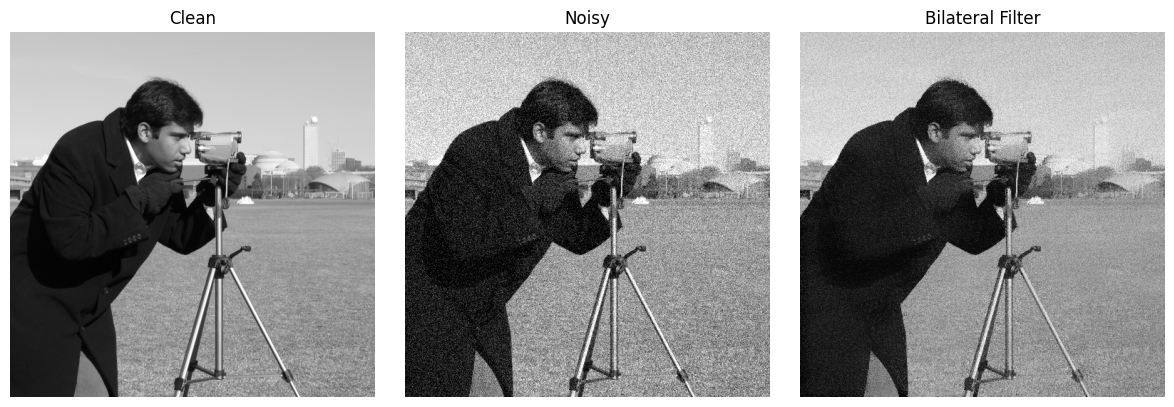

In [5]:
# Show the three images
show_images(
    [clean_image, noisy_image, denoised_image],
    ["Clean", "Noisy", "Bilateral Filter"]
)

In [6]:
# Save the noisy and denoised images
save_image(
    "../results/images/noisy_sigma25.png",
    noisy_image
)

save_image(
    "../results/images/bilateral_sigma25.png",
    denoised_image
)